# **Практическая работа №1**

Вариант 7

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
years = np.arange(1, 11)

y = np.array([
    134, 130, 128, 126, 122,
    120, 117, 112, 108, 105
], dtype=float)

print("Годы:", years)
print("Выпуск продукции:", y)

Годы: [ 1  2  3  4  5  6  7  8  9 10]
Выпуск продукции: [134. 130. 128. 126. 122. 120. 117. 112. 108. 105.]


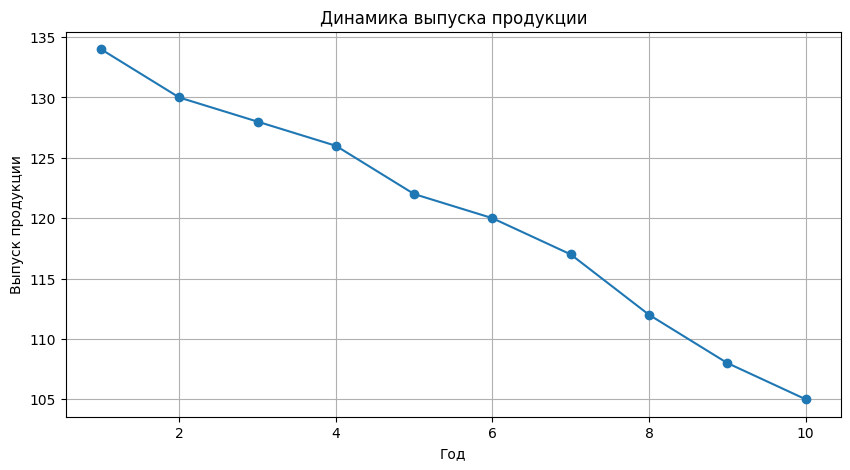

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(years, y, marker='o')

plt.xlabel("Год")
plt.ylabel("Выпуск продукции")
plt.title("Динамика выпуска продукции")
plt.grid()

plt.show()

# **Метод проверки разностей средних уровней.**

ВР разбивается на две примерно равные по числу уровней

In [ ]:
y1 = y[:5]
y2 = y[5:]

print("Первая часть:", y1)
print("Вторая часть:", y2)

Первая часть: [134. 130. 128. 126. 122.]
Вторая часть: [120. 117. 112. 108. 105.]


для каждой части вычисляются средние значения и дисперсии D1=σ1^2, D2=σ2^2

In [ ]:
mean1 = np.mean(y1)
mean2 = np.mean(y2)

print("Среднее первой части:", mean1)
print("Среднее второй части:", mean2)

Среднее первой части: 128.0
Среднее второй части: 112.4


In [ ]:
var1 = np.var(y1, ddof=1)
var2 = np.var(y2, ddof=1)

print("Дисперсия первой части:", var1)
print("Дисперсия второй части:", var2)

Дисперсия первой части: 20.0
Дисперсия второй части: 38.3


проверяется равенство (однородности) дисперсий обеих частей
ряда с помощью F – критерия Фишера

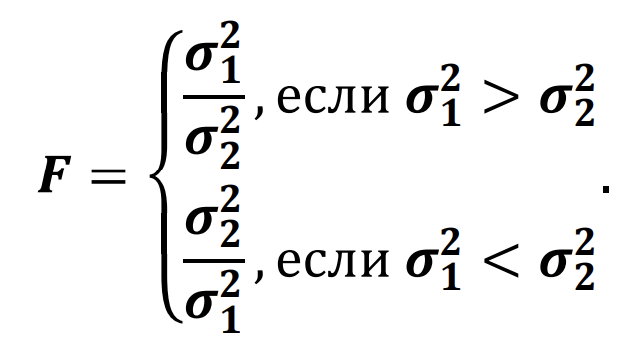

In [ ]:
F = max(var1, var2) / min(var1, var2)

print("F расчетное =", round(F, 3))

F расчетное = 1.915


Расчетное значение критерия F сравнивается с табличным (критическим) значением Fα с заданным уровнем значимости (уровнем ошибки) α. В качестве α возьмем значение α=0,05 . Величина (1–α) называется доверительной вероятностью.

In [ ]:
# Уровень значимости 5%
alpha = 0.05

# Количество значений в каждой части ряда
n1 = len(y1)
n2 = len(y2)

# Степени свободы
df1 = n1 - 1
df2 = n2 - 1

# Критическое значение критерия Фишера
F_critical = stats.f.ppf(1 - alpha, df1, df2)

print("F критическое =", round(F_critical, 3))

F критическое = 6.388


Если расчетное значение F < Fα, то гипотеза об однородности
дисперсий принимается и переходят к следующему этапу. Если F Fα , то
гипотеза об однородности дисперсий отклоняется, т.е. данный метод для
определения наличия тренда ответа не дает;

In [ ]:
if F < F_critical:
    print("F < Fкр: дисперсии можно считать однородными")
else:
    print("F >= Fкр: дисперсии неоднородны")

F < Fкр: дисперсии можно считать однородными


Гипотеза об однородности дисперсий принимается.

Значит, можем переходить к проверке тренда по критерию Стьюдента.

для начала расчитаем среднее квадратическое отклонение по формуле:

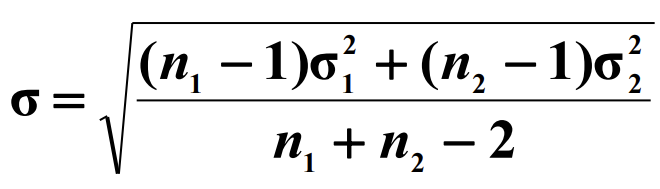

In [ ]:
n1 = len(y1)
n2 = len(y2)

pooled_var = ( (n1 - 1) * var1 + (n2 - 1) * var2 ) / (n1 + n2 - 2)

pooled_std = np.sqrt(pooled_var)

print("Среднеквадратическое отклонение:", pooled_std)

Среднеквадратическое отклонение: 5.399073994677235


определим расчетное значение t-критерия Стьюдента по формуле:

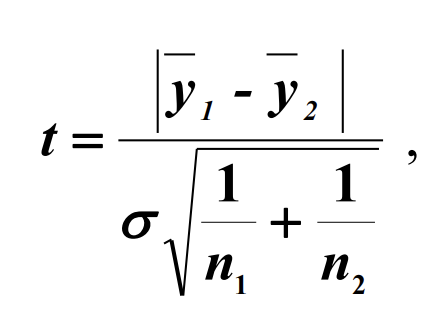

In [ ]:
t_calc = abs(mean1 - mean2) / ( pooled_std * np.sqrt(1/n1 + 1/n2) )

print("t расчетное =", t_calc)

t расчетное = 4.568517818727896


определим tα – табличное значение, которое берется для числа степеней свободы, равного n1+n2–2

In [ ]:
df = n1 + n2 - 2

t_critical = stats.t.ppf(1 - alpha / 2, df)

print("t критическое =", t_critical)

t критическое = 2.306004135204166


Если t > tα, то тренд есть.

In [ ]:
if t_calc > t_critical:
    print("t > tкр: тренд присутствует")
else:
    print("t <= tкр: статистически значимый тренд не обнаружен")

t > tкр: тренд присутствует


**тренд есть**

# **Построение трендовой модели**

In [ ]:
b, a = np.polyfit(years, y, 1)

print("a =", a)
print("b =", b)

a = 137.66666666666669
b = -3.175757575757577


polyfit подбирает полином, который лучше всего описывает мои точки.

Последняя 1 означает, что нужен полином первой степени.

А полином первой степени — это обычная прямая: $$ y=a+bt $$

То есть линейный тренд.

Получаем:

$$ y=137.667-3.176t $$

Вот это и есть построенная трендовая модель.

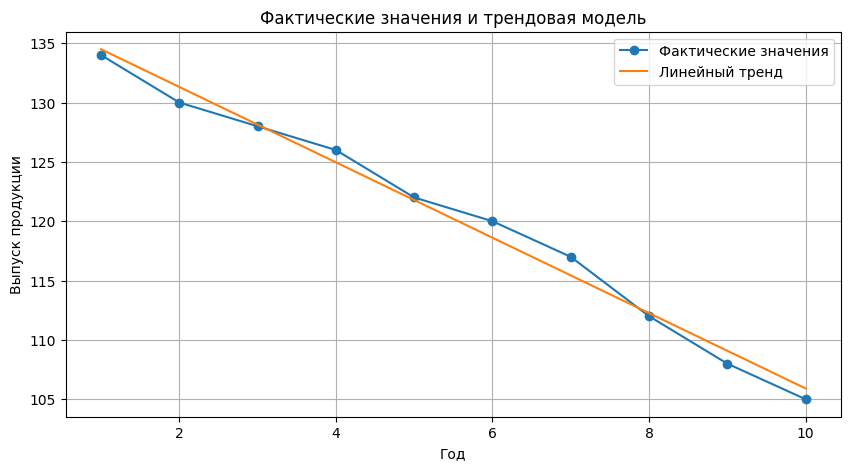

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    years,
    y,
    marker='o',
    label='Фактические значения'
)

plt.plot(
    years,
    y_trend,
    label='Линейный тренд'
)

plt.xlabel("Год")
plt.ylabel("Выпуск продукции")
plt.title("Фактические значения и трендовая модель")
plt.legend()
plt.grid()

plt.show()

Коэффицент = 3.176